## Names used in this notebook
- **tikh** = ordinary Tikhonov: ||Ax - y_delta||^2 + alpha ||x||^2
- **H1** = H1 penalty: ||Ax - y_delta||^2 + alpha (||x||^2 + ||Dx||^2)
- **H1_only** = only the derivative term: ||Ax - y_delta||^2 + alpha ||Dx||^2


## Problem 2 – Setup
- Consider the Abel problem for x(s) = s^(3/4) - 1
- Discretize K by a matrix A in R^(nxn), n = 1024
- Discretize similarly x(s) and y(t) = Kx(t) by x
- Add Gaussian noise e, 10%
- D matrix - operator 

## Problem 2(c) – Ordinary Tikhonov
- Find the solution to the ordinary Tikhonov problem (without D) for found alpha
- Plot the relative error
- optimal alpha? 

(1024, 1024)
[0.04419417 0.         0.         0.         0.        ]
[0.01332504 0.01473139 0.01670383 0.01976424 0.02551552 0.04419417
 0.         0.        ]


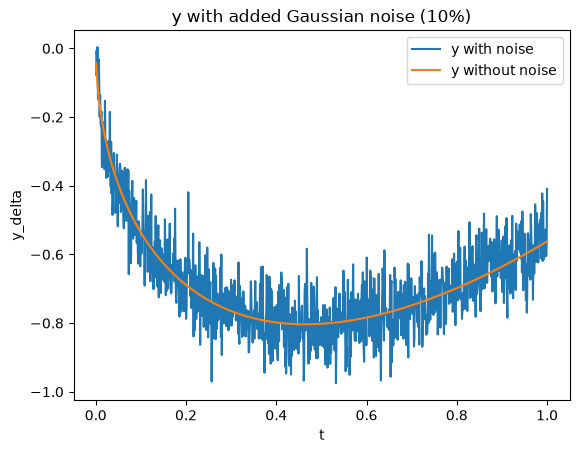

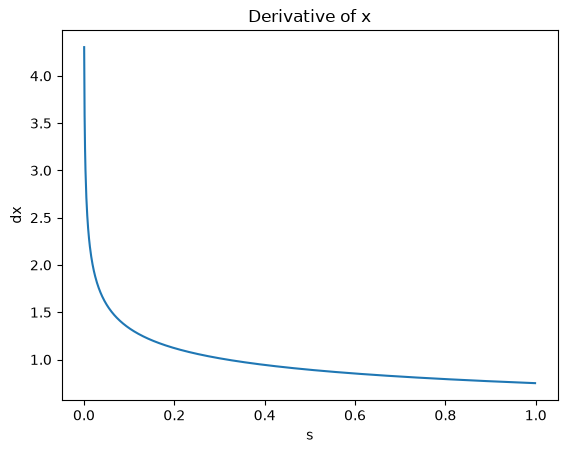

In [23]:
import numpy as np
import matplotlib.pyplot as plt 

n = 1024
h = 1/n
s_grid = np.zeros(n)
t_grid = np.zeros(n)

for i in range(n):
    s_grid[i] = (i+1/2)*h
    t_grid[i] = (i+1)*h

x_true = s_grid**(3/4) - 1


#kernel
def k(t,s):
    if s < t:
        return 1/np.sqrt(t-s)
    else:
        return 0


A = np.zeros((n,n))

#building A, A_ij = h K(t_i, s_j)
for i in range(n):
    for j in range(n):
        A[i,j] = h*k(t_grid[i], s_grid[j])
        

print(A.shape)
print(A[0,:5])
print(A[5,:8])

y = A @ x_true


np.random.seed(42)
e = np.random.normal(size=n)
d = e/np.linalg.norm(e)
e = d*0.1*np.linalg.norm(y)

y_delta = y + e

plt.plot(t_grid, y_delta, label ="y with noise")
plt.plot(t_grid, y, label ="y without noise")
plt.xlabel("t")
plt.ylabel("y_delta")
plt.title("y with added Gaussian noise (10%)")
plt.legend()
plt.show()

D = np.zeros((n-1,n))
for i in range(n-1):
    for j in range(n):
        if i == j:
            D[i,j] = n*(-1)
        elif i == j - 1:
            D[i,j] = n*(1)
        else:
            D[i,j] = 0

dx = D @ x_true #derivative
plt.plot(s_grid[:-1], dx) # x works on s_grid
plt.xlabel("s")
plt.ylabel("dx")
plt.title("Derivative of x")
plt.show()

        


In [24]:
# Ordinary Tikhonov
alphas = np.logspace(-8, 0, 50)        
errors_tikh = []                       

I = np.eye(n)


A_aug_tikh = np.zeros((2*n, n))
A_aug_tikh[:n, :] = A                   # top half: A (stays the same for every alpha)


y_aug_tikh = np.zeros(2*n)
y_aug_tikh[:n] = y_delta                

for alpha in alphas:
    A_aug_tikh[n:, :] = np.sqrt(alpha) * I                            
    x_alpha = np.linalg.lstsq(A_aug_tikh, y_aug_tikh, rcond=None)[0]  # least-squares solution
    err = np.linalg.norm(x_alpha - x_true) / np.linalg.norm(x_true)   
    errors_tikh.append(err)

tikh: minimal error = 0.10448344738578667 at alpha = 0.10481131341546852


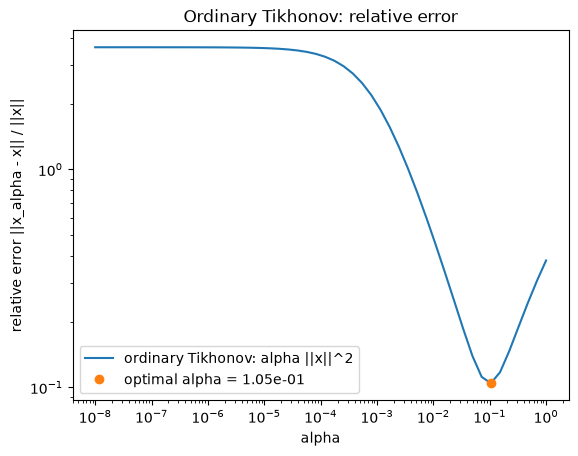

In [25]:
# optimal alpha for ordinary Tikhonov (tikh)
opt_index_tikh = np.argmin(errors_tikh)
alpha_opt_tikh = alphas[opt_index_tikh]
min_error_tikh = errors_tikh[opt_index_tikh]
print("tikh: minimal error =", min_error_tikh, "at alpha =", alpha_opt_tikh)

plt.loglog(alphas, errors_tikh, label="ordinary Tikhonov: alpha ||x||^2")
plt.loglog(alpha_opt_tikh, min_error_tikh, "o", label=f"optimal alpha = {alpha_opt_tikh:.2e}")
plt.xlabel("alpha")
plt.ylabel("relative error ||x_alpha - x|| / ||x||")
plt.title("Ordinary Tikhonov: relative error")
plt.legend()
plt.savefig("2cd_relative_error_vs_alpha.png", bbox_inches="tight", dpi=200)
plt.show()

In [26]:
# ordinary Tikhonov solution at its optimal alpha
A_aug_tikh[n:, :] = np.sqrt(alpha_opt_tikh) * I
x_tikh = np.linalg.lstsq(A_aug_tikh, y_aug_tikh, rcond=None)[0]

## Problem 2(d) – Tikhonov with H1 penalty

In [27]:
# penalty 
errors_H1 = []                              


A_aug_H1 = np.zeros((3*n - 1, n))
A_aug_H1[:n, :] = A                         


y_aug_H1 = np.zeros(3*n - 1)
y_aug_H1[:n] = y_delta                     

for alpha in alphas:
    A_aug_H1[n:2*n, :] = np.sqrt(alpha) * I            
    A_aug_H1[2*n:, :] = np.sqrt(alpha) * D             
    x_alpha = np.linalg.lstsq(A_aug_H1, y_aug_H1, rcond=None)[0]
    err = np.linalg.norm(x_alpha - x_true) / np.linalg.norm(x_true)   
    errors_H1.append(err)

H1:   minimal error = 0.02410753448302675 at alpha = 0.00025595479226995333
tikh: minimal error = 0.10448344738578667 at alpha = 0.10481131341546852


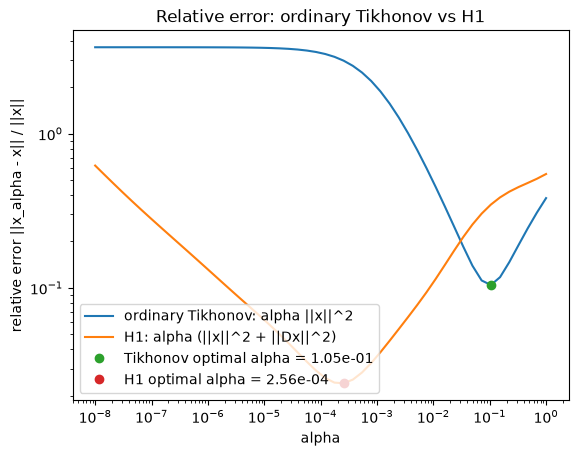

In [28]:

opt_index_H1 = np.argmin(errors_H1)
alpha_opt_H1 = alphas[opt_index_H1]
min_error_H1 = errors_H1[opt_index_H1]
print("H1:   minimal error =", min_error_H1, "at alpha =", alpha_opt_H1)
print("tikh: minimal error =", min_error_tikh, "at alpha =", alpha_opt_tikh)

# both error curves in one plot
plt.loglog(alphas, errors_tikh, label="ordinary Tikhonov: alpha ||x||^2")
plt.loglog(alphas, errors_H1, label="H1: alpha (||x||^2 + ||Dx||^2)")
plt.loglog(alpha_opt_tikh, min_error_tikh, "o", label=f"Tikhonov optimal alpha = {alpha_opt_tikh:.2e}")
plt.loglog(alpha_opt_H1, min_error_H1, "o", label=f"H1 optimal alpha = {alpha_opt_H1:.2e}")
plt.xlabel("alpha")
plt.ylabel("relative error ||x_alpha - x|| / ||x||")
plt.title("Relative error: ordinary Tikhonov vs H1")
plt.legend(loc="lower left")
plt.savefig("2d_relative_error_tikh_vs_H1.png", bbox_inches="tight", dpi=200)
plt.show()


A_aug_H1[n:2*n, :] = np.sqrt(alpha_opt_H1) * I
A_aug_H1[2*n:, :] = np.sqrt(alpha_opt_H1) * D
x_H1 = np.linalg.lstsq(A_aug_H1, y_aug_H1, rcond=None)[0]

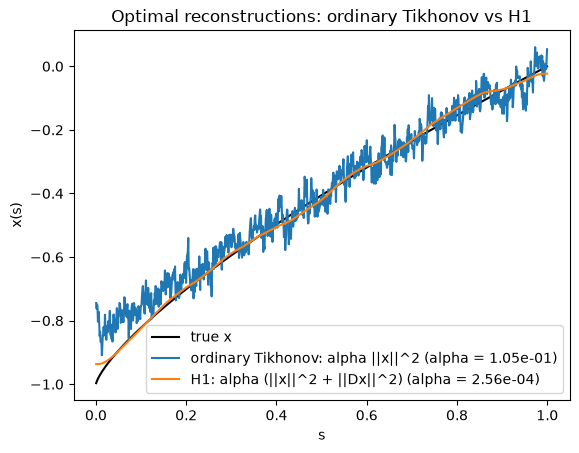

In [29]:
plt.plot(s_grid, x_true, "k", label="true x")
plt.plot(s_grid, x_tikh, label=f"ordinary Tikhonov: alpha ||x||^2 (alpha = {alpha_opt_tikh:.2e})")
plt.plot(s_grid, x_H1, label=f"H1: alpha (||x||^2 + ||Dx||^2) (alpha = {alpha_opt_H1:.2e})")
plt.xlabel("s")
plt.ylabel("x(s)")
plt.title("Optimal reconstructions: ordinary Tikhonov vs H1")
plt.legend()
plt.savefig("2d_optimal_reconstruction_tikh_H1.png", bbox_inches="tight", dpi=200)
plt.show()

## Using only the derivative term, matrix D H1 only


In [30]:
# H1 only
alphas_H1_only = np.logspace(-15, -3, 50)       
errors_H1_only = []                             

A_aug_H1_only = np.zeros((2*n - 1, n))
A_aug_H1_only[:n, :] = A                


y_aug_H1_only = np.zeros(2*n - 1)
y_aug_H1_only[:n] = y_delta                   

for alpha in alphas_H1_only:
    A_aug_H1_only[n:, :] = np.sqrt(alpha) * D                            
    x_alpha = np.linalg.lstsq(A_aug_H1_only, y_aug_H1_only, rcond=None)[0] 
    err = np.linalg.norm(x_alpha - x_true) / np.linalg.norm(x_true)       
    errors_H1_only.append(err)

H1_only: minimal error = 0.02422233766996677 at alpha = 0.00018420699693267163


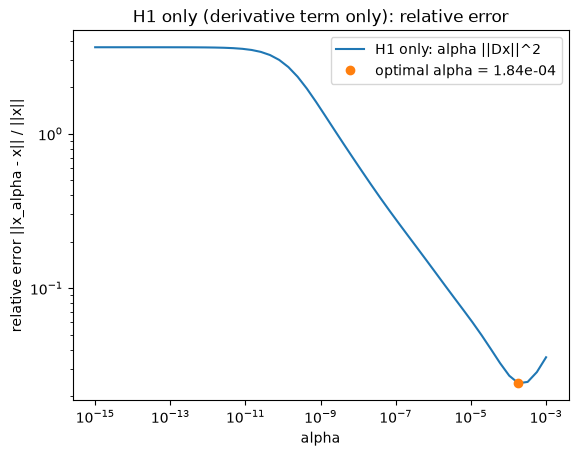

In [31]:
# optimal alpha for H1 only
opt_index_H1_only = np.argmin(errors_H1_only)
alpha_opt_H1_only = alphas_H1_only[opt_index_H1_only]
min_error_H1_only = errors_H1_only[opt_index_H1_only]
print("H1_only: minimal error =", min_error_H1_only, "at alpha =", alpha_opt_H1_only)

plt.loglog(alphas_H1_only, errors_H1_only, label="H1 only: alpha ||Dx||^2")
plt.loglog(alpha_opt_H1_only, min_error_H1_only, "o", label=f"optimal alpha = {alpha_opt_H1_only:.2e}")
plt.xlabel("alpha")
plt.ylabel("relative error ||x_alpha - x|| / ||x||")
plt.title("H1 only (derivative term only): relative error")
plt.legend()
plt.savefig("2cd_relative_error_vs_alpha_H1_only.png", bbox_inches="tight", dpi=200)
plt.show()

## Problem 3 - Large-scale deblurring of a real image with the 2D heat equation

### 3(a) - Memory

In [32]:
m = 512
n_pixels = m**2                    # number of pixels = length of the vector x
memory_bytes = 8 * n_pixels**2     # A is n_pixels x n_pixels, 8 bytes per number
memory_GB = memory_bytes / (1024**3)
print(f"Image = {m} x {m}, Memory = {memory_GB:.2f} GiB")

# A as a dense matrix would need 512 GiB, far more than 16 GB of RAM
# so we only store the damping factors and apply A = S^T Lambda S with dstn / idstn

Image = 512 x 512, Memory = 512.00 GiB


### 3(b) - what to do:
- Set up A with the sine transform and check it on a basis function
- Load the image, values in [0, 1], black = 0
- Blur it: y = A(x)
- Add noise with ||e|| = 0.01 ||y||
- Show x and y_delta side by side

In [33]:
from scipy.fft import dstn, idstn

N = 512
T = 0.001

# forward operator A = S^T Lambda S (from the assignment)
S = lambda x: dstn(x, type=2, norm='ortho')
ST = lambda x: idstn(x, type=2, norm='ortho')
freq = np.arange(1, N + 1)
lam = np.exp(-(freq[:, None]**2 + freq[None, :]**2) * T)
A2d = lambda x: ST(lam * S(x))

# pixel-centre grid
s_grid = np.zeros(N)
for i in range(N):
    s_grid[i] = (i + 1/2) * np.pi / N

# check on a basis function sin(k s1) sin(l s2)
k = 3
l = 5
x_test = np.zeros((N, N))
for i in range(N):
    for j in range(N):
        x_test[i, j] = np.sin(k * s_grid[i]) * np.sin(l * s_grid[j])

expected = np.exp(-(k**2 + l**2) * T) * x_test
print("max error:", np.max(np.abs(A2d(x_test) - expected)))

max error: 1.7763568394002505e-15


In [34]:
from skimage import data
from skimage.transform import resize

brain = data.brain()           # 10 MRI slices
x_true = brain[5]              # slice index 5
x_true = x_true / x_true.max() # values in [0, 1], black = 0
x_true = resize(x_true, (N, N))
print(x_true.shape)

(512, 512)


check: 0.01


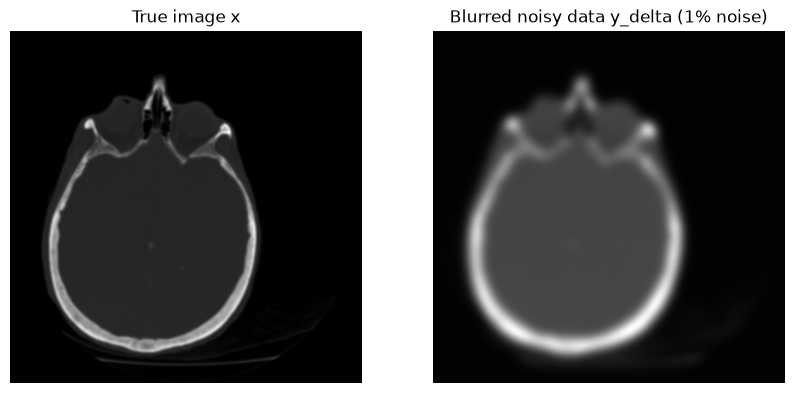

In [35]:
y = A2d(x_true)

# noise with ||e|| = 0.01 ||y||
np.random.seed(42)
e = np.random.randn(N, N)
e = e / np.linalg.norm(e)
e = e * 0.01 * np.linalg.norm(y)

y_delta = y + e
print("check:", np.linalg.norm(e) / np.linalg.norm(y))

fig, ax = plt.subplots(1, 2, figsize=(10, 5))
ax[0].imshow(x_true, cmap="gray")
ax[0].set_title("True image x")
ax[0].axis("off")
ax[1].imshow(y_delta, cmap="gray")
ax[1].set_title("Blurred noisy data y_delta (1% noise)")
ax[1].axis("off")
plt.savefig("3b_x_and_ydelta.png", bbox_inches="tight")
plt.show()

### 3(c) - what to do:
- Run 200 iterations of CGLS (from week 8) on Ax = y_delta, starting from x[0] = 0
- Plot the relative error against k and find the optimal k
- Show the images for k = 5, 20, optimal k and 200

In [36]:
x = np.zeros_like(y_delta)    # x[0] = 0
r = y_delta.copy()            # r[0] = y_delta - A x[0]
ATr = A2d(r)                  # A^T r  (A^T = A)
d = ATr.copy()

kmax = 200
errors = []
residuals = []

keep = [5, 20, 141, 200]      # iterations whose images we want (141 = optimal k found before)
saved = {}

for k in range(1, kmax + 1):
    Ad = A2d(d)
    alpha = np.linalg.norm(ATr)**2 / np.linalg.norm(Ad)**2
    x = x + alpha * d
    r = r - alpha * Ad

    ATr_new = A2d(r)
    beta = np.linalg.norm(ATr_new)**2 / np.linalg.norm(ATr)**2
    d = ATr_new + beta * d
    ATr = ATr_new

    errors.append(np.linalg.norm(x - x_true) / np.linalg.norm(x_true))
    residuals.append(np.linalg.norm(r))

    if k in keep:
        saved[k] = x.copy()

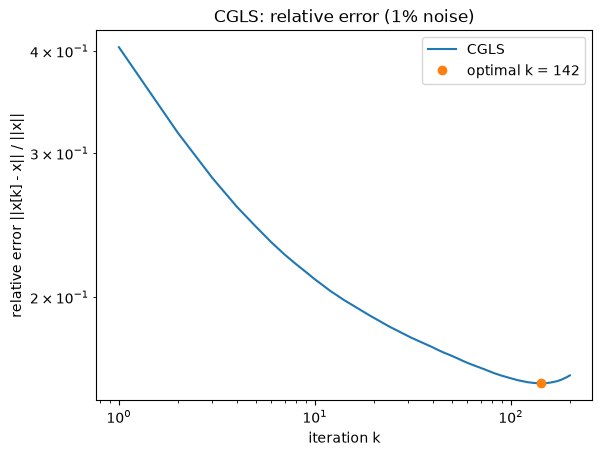

optimal k: 142
smallest error: 0.15691143198240284
error at k = 200: 0.16042376203373904


In [37]:
k_opt = np.argmin(errors) + 1      # +1 because k starts at 1
min_error = errors[k_opt - 1]

k_values = np.arange(1, kmax + 1)

plt.loglog(k_values, errors, label="CGLS")
plt.loglog(k_opt, min_error, "o", label=f"optimal k = {k_opt}")
plt.xlabel("iteration k")
plt.ylabel("relative error ||x[k] - x|| / ||x||")
plt.title("CGLS: relative error (1% noise)")
plt.legend()
plt.savefig("3c_relative_error_vs_k.png", bbox_inches="tight")
plt.show()

print("optimal k:", k_opt)
print("smallest error:", min_error)
print("error at k = 200:", errors[-1])

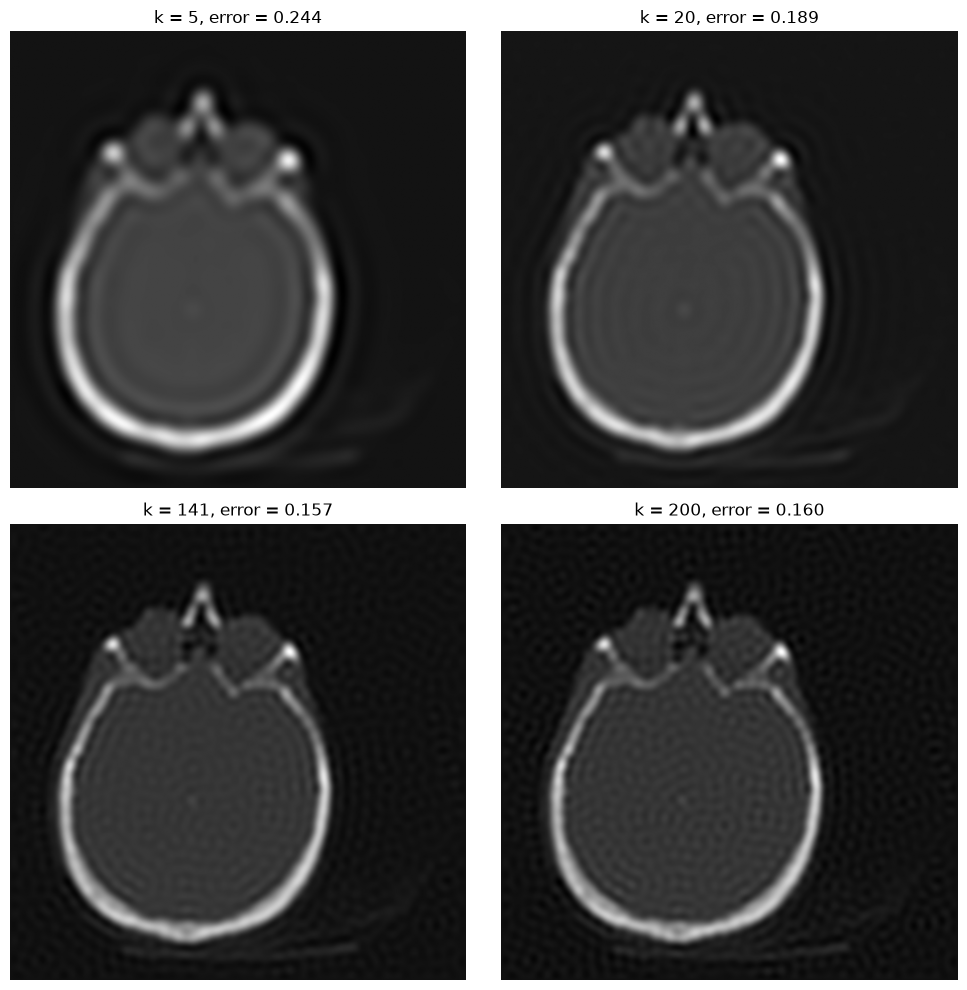

In [38]:
fig, ax = plt.subplots(2, 2, figsize=(10, 10))
for i, a in enumerate(ax.flat):
    k = keep[i]
    a.imshow(saved[k], cmap="gray")
    a.set_title(f"k = {k}, error = {errors[k-1]:.3f}")
    a.axis("off")
plt.tight_layout()
plt.savefig("3c_4_reconstructions.png", bbox_inches="tight")
plt.show()